# Load the tests to compare

In [21]:
%matplotlib inline
import os
import sys
import json
import pickle
import pandas as pd
import matplotlib.pyplot as plt

__file__ = globals()['_dh'][0]

# get an absolute path to the directory that contains parent files
project_dir = __file__ = globals()['_dh'][0]
sys.path.append(os.path.normpath(os.path.join(project_dir, '..', '..')))

from experiments.utils.constants import TESTS_RESULTS_PATH
series = 73
start_test = 0
end_test = 27
tests_ids = [i for i in range(start_test, end_test)]
tests_names = [i for i in range(start_test, end_test)]

tests = {}


for test_id, test_name in zip(tests_ids, tests_names):
    test_path = os.path.join(
        TESTS_RESULTS_PATH,
        'series',
        str(series),
        'tests',
        str(test_id))
    with open(os.path.join(test_path, 'info.json')) as cf:
        info = json.loads(cf.read())
    with open(os.path.join(test_path, 'episodes.pickle'), 'rb') as input_file:
        episodes = pickle.load(input_file)
    tests.update({test_name: {
        'info': info,
        'episodes': episodes
    }})
test_types = [test['info']['algorithm'] for _, test in tests.items()]
print("availeble tests:\n {}\ntests_types:\n {}".format(
    list(tests.keys()),
    test_types))

availeble tests:
 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
tests_types:
 ['IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA', 'IMPALA']


# Necessary stats of a test

In [22]:
final_stats = []
for test_id in range(start_test, end_test):
    users_distances_episodes_average = [episode['users_distances'].mean() for episode in tests[test_id]['episodes']]
    users_distances_test_average = sum(users_distances_episodes_average) / len(users_distances_episodes_average)
    num_consolidated_episodes_average = [episode['num_consolidated'].mean() for episode in tests[test_id]['episodes']]
    num_consolidated_test_average = sum(num_consolidated_episodes_average) / len(num_consolidated_episodes_average)
    # print(users_distances_episodes_average)
    # print(users_distances_test_average)
    # print(num_consolidated_episodes_average)
    # print(num_consolidated_test_average)
    final_stats.append({
        'test_id': test_id,
        # 'checkpoint': tests[test_id]['info']['checkpoint'],
        'network_id': tests[test_id]['info']['network_id'],
        'network_id_test': tests[test_id]['info']['network_id_test'],
        'trace_id_test': tests[test_id]['info']['trace_id_test'],
        'sample_episode_users_distances': tests[test_id]['episodes'][0]['users_distances'],
        'sample_episode_num_consolidated': tests[test_id]['episodes'][0]['num_consolidated'],
        # 'experiments': tests[test_id]['info']['experiments'],
        'penalty_latency': tests[test_id]['info']['penalty_latency'],
        'penalalty_consolidated': tests[test_id]['info']['penalty_consolidated'],
        'users_distances_test_average': users_distances_test_average,
        'num_consolidated_test_average': num_consolidated_test_average
    })

final_stats_df = pd.DataFrame(final_stats)
final_stats_df['test_types'] = test_types
# final_stats_df.loc[df['penalalty_consolidated']]

# TODO add the following information to the table (from the info.json file)
# - penatly_latency
# - penalty_conslidation

# compare tests - tables

In [23]:
final_stats_df

,test_id,network_id,network_id_test,trace_id_test,sample_episode_users_distances,sample_episode_num_consolidated,penalty_latency,penalalty_consolidated,users_distances_test_average,num_consolidated_test_average,test_types
0,0,1,1,0,0 0.685288 1 0.635435 2 0.64...,0 6 1 6 2 6 3 6 4 ...,4,4,0.648368,5.999421,IMPALA
1,1,1,11,0,0 0.873798 1 0.891464 2 0.87...,0 6 1 6 2 6 3 6 4 ...,4,4,0.782594,6.000000,IMPALA
2,2,1,12,0,0 0.869885 1 0.872082 2 0.86...,0 6 1 6 2 6 3 6 4 ...,4,4,0.817866,6.000000,IMPALA
3,3,1,13,0,0 0.947351 1 0.892774 2 0.96...,0 6 1 6 2 6 3 6 4 ...,4,4,0.832932,6.000000,IMPALA
4,4,1,14,0,0 1.425752 1 1.502246 2 1.42...,0 6 1 6 2 6 3 6 4 ...,4,4,1.375796,6.000000,IMPALA
5,5,1,15,0,0 1.473729 1 1.549312 2 1.47...,0 6 1 6 2 6 3 6 4 ...,4,4,1.480520,5.999710,IMPALA
6,6,1,16,0,0 1.473061 1 1.548511 2 1.47...,0 6 1 6 2 6 3 6 4 ...,4,4,1.477645,5.999710,IMPALA
7,7,1,17,0,0 1.418520 1 1.493970 2 1.41...,0 6 1 6 2 6 3 6 4 ...,4,4,1.492846,5.999421,IMPALA
8,8,1,18,0,0 1.454633 1 1.585977 2 1.50...,0 6 1 6 2 6 3 6 4 ...,4,4,1.583836,5.999421,IMPALA
9,9,5,19,0,0 1.298836 1 1.320536 2 1.27...,0 6 1 6 2 6 3 6 4 ...,4,4,1.318361,5.953953,IMPALA


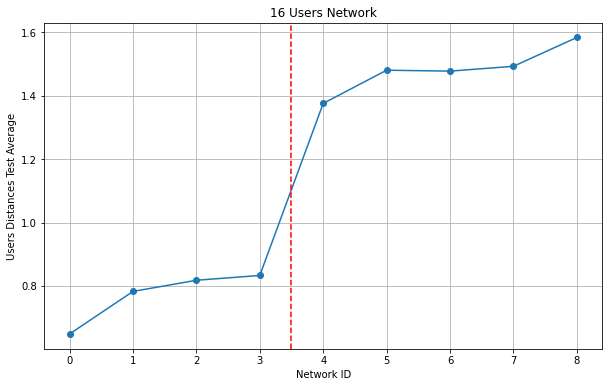

In [24]:
import matplotlib.pyplot as plt

# Assuming final_stats_df is your DataFrame
subset_df = final_stats_df[final_stats_df["network_id"] == 1][["test_id", "users_distances_test_average"]]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
plt.axvline(x=3.5, color='r', linestyle='--')  # Draw a vertical dashed red line between test_id 3 and 4
plt.title("16 Users Network")  # Adjusted title to reflect the updated network ID
plt.xlabel("Network ID")
plt.ylabel("Users Distances Test Average")
plt.grid(True)
plt.show()


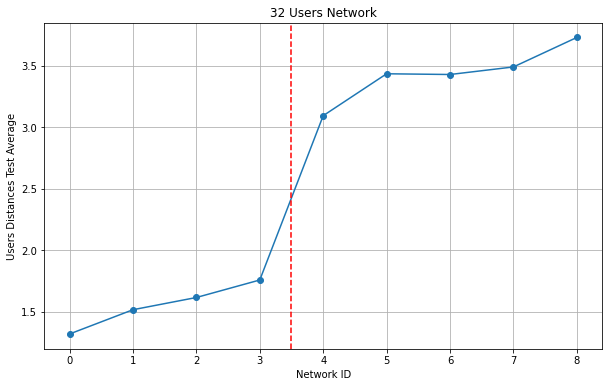

In [25]:
import matplotlib.pyplot as plt

# Assuming final_stats_df is your DataFrame
subset_df = final_stats_df[final_stats_df["network_id"] == 5][["test_id", "users_distances_test_average"]]

# Restart network IDs from 0 after filtering
subset_df["test_id"] -= subset_df["test_id"].min()

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
plt.axvline(x=3.5, color='r', linestyle='--')  # Draw a vertical dashed red line between test_id 3 and 4
plt.title("32 Users Network")  # Adjusted title to reflect the updated network ID
plt.xlabel("Network ID")
plt.ylabel("Users Distances Test Average")
plt.grid(True)
plt.show()


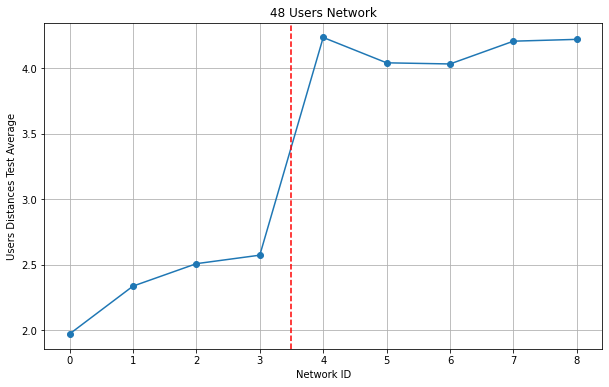

In [26]:
import matplotlib.pyplot as plt

# Assuming final_stats_df is your DataFrame
subset_df = final_stats_df[final_stats_df["network_id"] == 6][["test_id", "users_distances_test_average"]]

# Restart network IDs from 0 after filtering
subset_df["test_id"] -= subset_df["test_id"].min()

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
plt.axvline(x=3.5, color='r', linestyle='--')  # Draw a vertical dashed red line between test_id 3 and 4
plt.title("48 Users Network")  # Adjusted title to reflect the updated network ID
plt.xlabel("Network ID")
plt.ylabel("Users Distances Test Average")
plt.grid(True)
plt.show()

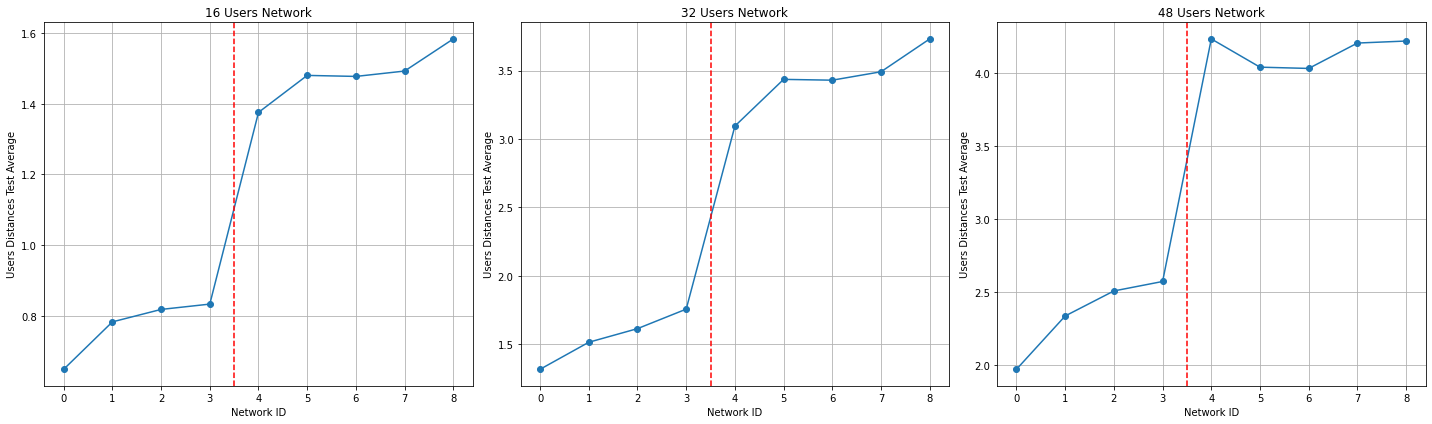

In [27]:
import matplotlib.pyplot as plt

# Set up subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 6))

# Plotting for the first network (16 Users Network)
subset_df = final_stats_df[final_stats_df["network_id"] == 1][["test_id", "users_distances_test_average"]]
axs[0].plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
axs[0].axvline(x=3.5, color='r', linestyle='--')
axs[0].set_title("16 Users Network")
axs[0].set_xlabel("Network ID")
axs[0].set_ylabel("Users Distances Test Average")
axs[0].grid(True)

# Plotting for the second network (32 Users Network)
subset_df = final_stats_df[final_stats_df["network_id"] == 5][["test_id", "users_distances_test_average"]]
subset_df["test_id"] -= subset_df["test_id"].min()  # Restart test IDs from 0
axs[1].plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
axs[1].axvline(x=3.5, color='r', linestyle='--')
axs[1].set_title("32 Users Network")
axs[1].set_xlabel("Network ID")
axs[1].set_ylabel("Users Distances Test Average")
axs[1].grid(True)

# Plotting for the third network (48 Users Network)
subset_df = final_stats_df[final_stats_df["network_id"] == 6][["test_id", "users_distances_test_average"]]
subset_df["test_id"] -= subset_df["test_id"].min()  # Restart test IDs from 0
axs[2].plot(subset_df["test_id"], subset_df["users_distances_test_average"], marker='o', linestyle='-')
axs[2].axvline(x=3.5, color='r', linestyle='--')
axs[2].set_title("48 Users Network")
axs[2].set_xlabel("Network ID")
axs[2].set_ylabel("Users Distances Test Average")
axs[2].grid(True)

# Adjust layout
plt.tight_layout()
plt.show()
